In [1]:
!pip install pymongo pandas numpy scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 331.1/331.1 kB 15.3 MB/s eta 0:00:00


In [8]:
from pymongo import MongoClient
import pandas as pd
import os
from google.colab import userdata

# Retrieve MongoDB connection string from Colab secrets
MONGO_URI = userdata.get('MONGO_URI')

# Establish connection to MongoDB
client = MongoClient(MONGO_URI)

# Select database and collection
db = client["SphereSleep"]
sensor_collection = db["sensor_data"]

In [9]:
# Fetch all records from MongoDB collection
data = list(sensor_collection.find())

# Convert to Pandas DataFrame
df = pd.DataFrame(data)

# View first rows
df.head()

,timestamp,user_id,_id,light_intensity,temperature,humidity,session_id,sound_level,distance,motion_detected
0,1970-01-01 00:00:05,user_001,69dbbef1fc40429a25bbc909,77.50,25.0,50.0,sleep_19700101_user001,18,0,0
1,1970-01-01 00:00:47,user_001,69debb2cb54b747ea1f37c52,4.17,25.0,50.0,sleep_19700101_user001,26,6,1
2,1970-01-01 00:00:49,user_001,69debb30b54b747ea1f37c53,4.17,25.0,50.0,sleep_19700101_user001,39,6,1
3,2026-04-01 21:45:03,user_001,69cd91e2fd35102c3c5ac1d1,5.00,27.5,55.3,sleep_20260401_user001,14,0,0
4,2026-04-01 21:45:04,user_001,69cd91e4fd35102c3c5ac1d2,5.00,27.5,55.3,sleep_20260401_user001,28,0,0


In [10]:
# Sort data by timestamp (important for time-series analysis)
df = df.sort_values("timestamp")

# Filter out invalid/old timestamps
df = df[df['timestamp'] > pd.to_datetime('2020-01-01 00:00:00')]

# Set timestamp as index for resampling
df = df.set_index("timestamp")

In [11]:
df.columns

Index(['user_id', '_id', 'light_intensity', 'temperature', 'humidity',
       'session_id', 'sound_level', 'distance', 'motion_detected'],
      dtype='object')

# Feature Set

In [13]:
features = [
    "temperature",
    "humidity",
    "sound_level",
    "light_intensity",
    "motion_detected",
    "distance"
]

df.shape

(61315, 9)

In [14]:
df = df.dropna()

df.shape

(61315, 9)

In [15]:
X = df[features].values

In [16]:
X

array([[ 27.5 ,  55.3 ,  14.  ,   5.  ,   0.  ,   0.  ],
       [ 27.5 ,  55.3 ,  28.  ,   5.  ,   0.  ,   0.  ],
       [ 26.6 ,  56.  ,  41.  ,   4.17,   1.  ,   0.  ],
       ...,
       [ 25.  ,  50.  , 183.  ,  28.33,   0.  ,   9.  ],
       [ 25.  ,  50.  , 183.  ,  28.33,   0.  ,   9.  ],
       [ 25.  ,  50.  , 181.  ,  29.17,   0.  ,   9.  ]])

# Scale data

In [18]:
#Stop model from getting biased
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [19]:
X_scaled

array([[ 0.25716094, -0.44687013, -1.5090465 , -0.27794669, -0.22256905,
        -0.36507212],
       [ 0.25716094, -0.44687013, -1.25737731, -0.27794669, -0.22256905,
        -0.36507212],
       [-0.14486635, -0.38192471, -1.02368448, -0.30728653,  4.4929877 ,
        -0.36507212],
       ...,
       [-0.85958155, -0.93859973,  1.52896021,  0.54675008, -0.22256905,
        -0.1095522 ],
       [-0.85958155, -0.93859973,  1.52896021,  0.54675008, -0.22256905,
        -0.1095522 ],
       [-0.85958155, -0.93859973,  1.49300747,  0.5764434 , -0.22256905,
        -0.1095522 ]])

# Train the model (Unsupervised learing)

In [20]:
# Assume about 10% of the dataset will be classified as anomalies after scoring
from sklearn.ensemble import IsolationForest

model = IsolationForest(
    n_estimators=100,
    contamination=0.1,  # assume 10% anomalies
    random_state=42
)

model.fit(X_scaled)

IsolationForest(contamination=0.1, random_state=42)

In [24]:
pred = model.predict(X_scaled)
pred

array([ 1,  1, -1, ...,  1,  1,  1])

In [25]:
df["anomaly"] = pred

In [26]:
df

,user_id,_id,light_intensity,temperature,humidity,session_id,sound_level,distance,motion_detected,anomaly
timestamp,,,,,,,,,,
2026-04-01 21:45:03,user_001,69cd91e2fd35102c3c5ac1d1,5.00,27.5,55.3,sleep_20260401_user001,14,0,0,1
2026-04-01 21:45:04,user_001,69cd91e4fd35102c3c5ac1d2,5.00,27.5,55.3,sleep_20260401_user001,28,0,0,1
2026-04-01 21:45:05,user_001,69cd91e5fd35102c3c5ac1d3,4.17,26.6,56.0,sleep_20260401_user001,41,0,1,-1
2026-04-01 21:45:07,user_001,69cd91e6fd35102c3c5ac1d4,5.00,26.6,56.0,sleep_20260401_user001,55,0,0,1
2026-04-01 21:45:08,user_001,69cd91e8fd35102c3c5ac1d5,4.17,26.6,56.0,sleep_20260401_user001,68,0,1,-1
...,...,...,...,...,...,...,...,...,...,...
2026-04-16 02:48:30,user_001,69e04dff53563f4013defd9d,28.33,25.0,50.0,sleep_20260416_user001,181,9,0,1
2026-04-16 02:48:32,user_001,69e04e0153563f4013defd9e,28.33,25.0,50.0,sleep_20260416_user001,182,9,0,1
2026-04-16 02:48:34,user_001,69e04e0253563f4013defd9f,28.33,25.0,50.0,sleep_20260416_user001,183,9,0,1


In [27]:
import joblib

joblib.dump(model, "anomaly_model.pkl")

['anomaly_model.pkl']

In [28]:
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

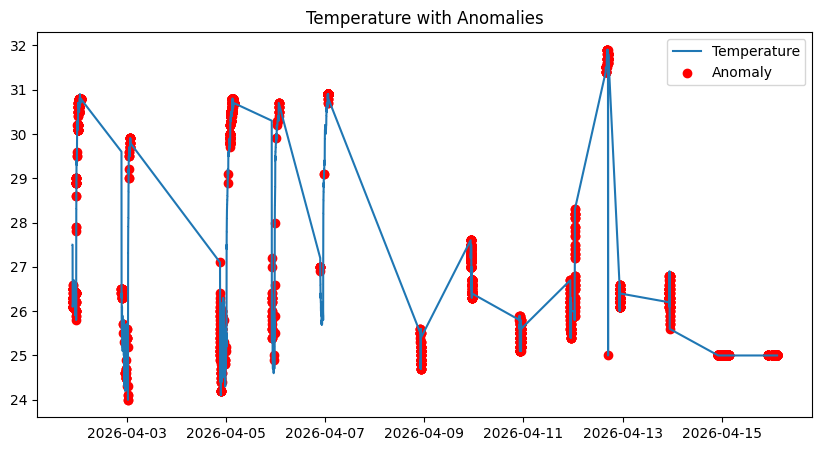

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(df.index, df["temperature"], label="Temperature")

# highlight anomalies
anomalies = df[df["anomaly"] == -1]
plt.scatter(anomalies.index, anomalies["temperature"], color="red", label="Anomaly")

plt.legend()
plt.title("Temperature with Anomalies")
plt.show()

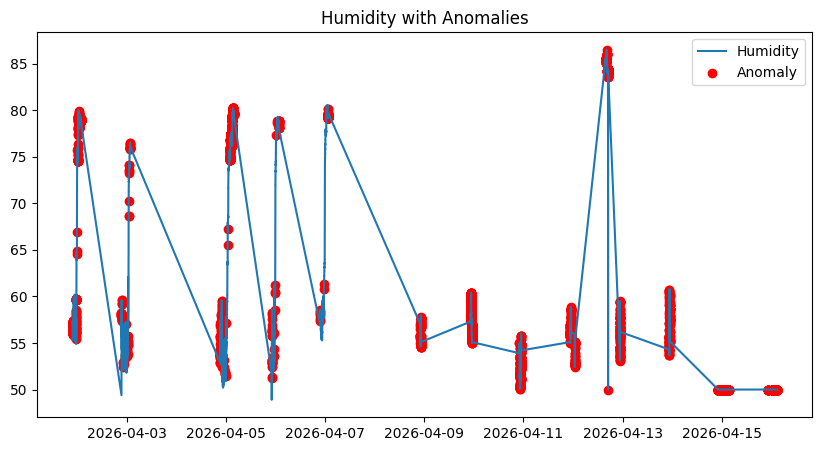

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(df.index, df["humidity"], label="Humidity")

# highlight anomalies
anomalies = df[df["anomaly"] == -1]
plt.scatter(anomalies.index, anomalies["humidity"], color="red", label="Anomaly")

plt.legend()
plt.title("Humidity with Anomalies")
plt.show()

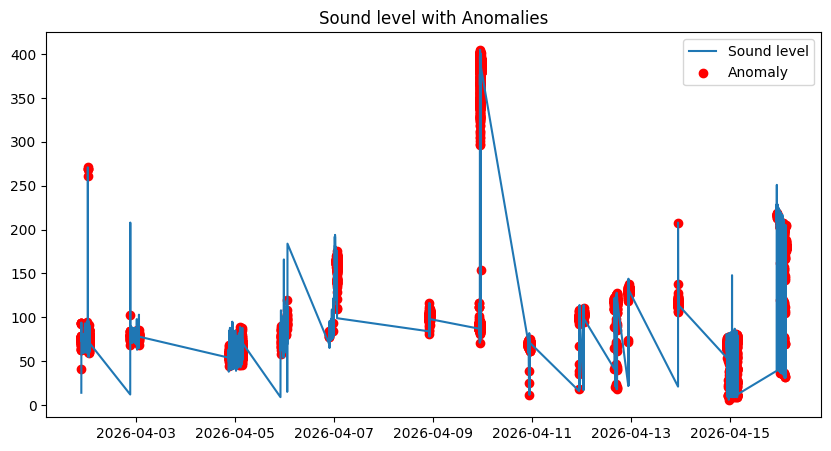

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(df.index, df["sound_level"], label="Sound level")

# highlight anomalies
anomalies = df[df["anomaly"] == -1]
plt.scatter(anomalies.index, anomalies["sound_level"], color="red", label="Anomaly")

plt.legend()
plt.title("Sound level with Anomalies")
plt.show()

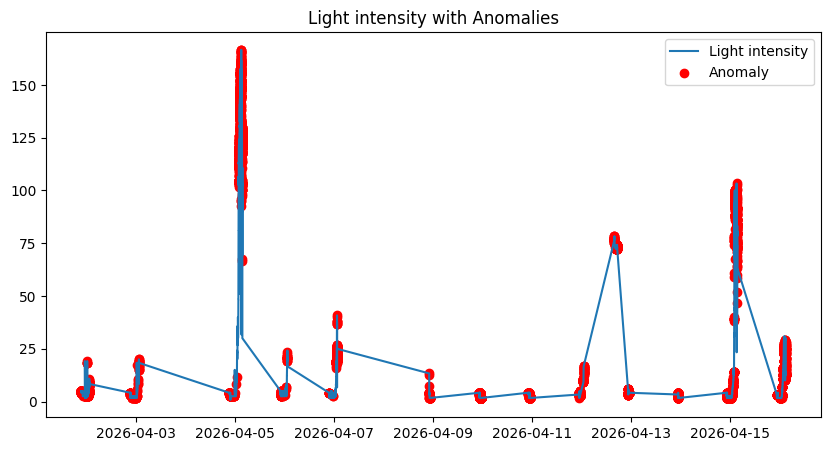

In [33]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(df.index, df["light_intensity"], label="Light intensity")

# highlight anomalies
anomalies = df[df["anomaly"] == -1]
plt.scatter(anomalies.index, anomalies["light_intensity"], color="red", label="Anomaly")

plt.legend()
plt.title("Light intensity with Anomalies")
plt.show()

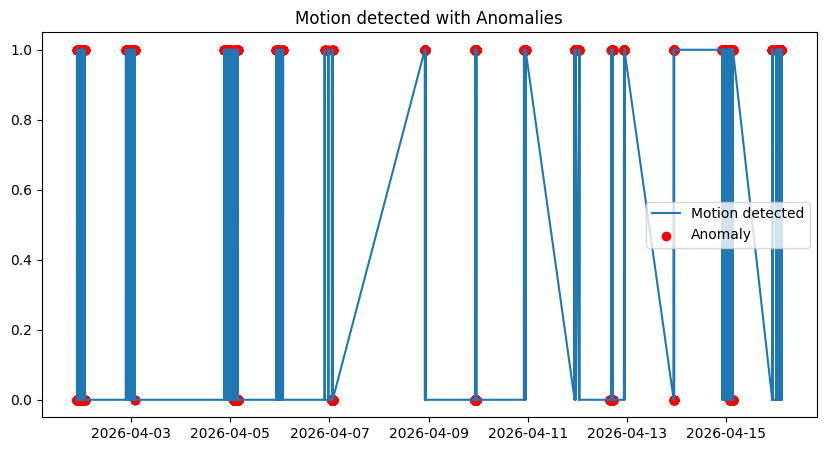

In [38]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(df.index, df["motion_detected"], label="Motion detected")

# highlight anomalies
anomalies = df[df["anomaly"] == -1]
plt.scatter(anomalies.index, anomalies["motion_detected"], color="red", label="Anomaly")

plt.legend()
plt.title("Motion detected with Anomalies")
plt.show()

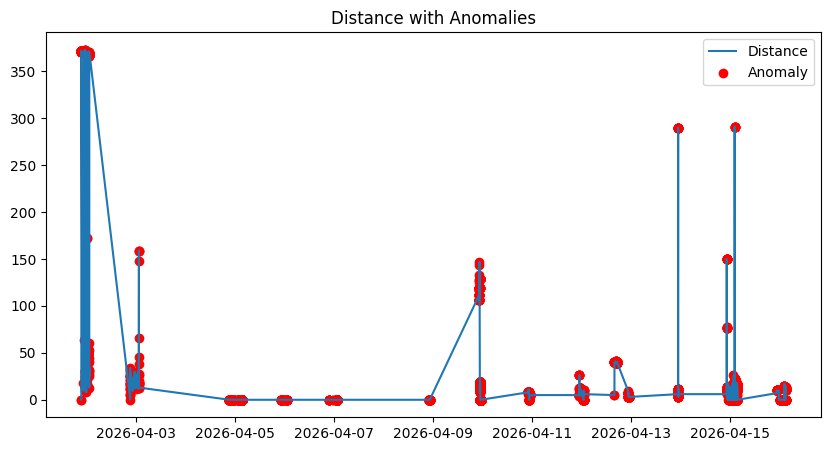

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))

plt.plot(df.index, df["distance"], label="Distance")

# highlight anomalies
anomalies = df[df["anomaly"] == -1]
plt.scatter(anomalies.index, anomalies["distance"], color="red", label="Anomaly")

plt.legend()
plt.title("Distance with Anomalies")
plt.show()